In [2]:
import polars as pl
import pandas as pd
import networkx as nx
import igraph as ig
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def read_graph(path) -> dict:

    edgelist = pl.read_parquet(path)
    
    graph = nx.from_pandas_edgelist(
        edgelist.to_pandas(), source="source", target="target", edge_attr="mi"
    )
    return graph

def plot_mi_distribution(path_edge):
    vals = (
        pl.read_parquet(path_edge)
        .get_column("mi")
        .drop_nulls()
        .to_numpy()
    )
    
    sns.histplot(x=vals, bins=40)
    plt.xlabel("Mutual information (MI)")
    plt.ylabel("Number of edges")
    plt.yscale("log")
    plt.title("Distribution of edge MI values")
    plt.show()
    

path_edge= "../output/network/edgelist_vip_test.parquet"
    
edgelist = pl.read_parquet(path_edge)    
   

In [7]:
mi_df= pl.read_parquet("../output/network/mi_matrix_vip_test.parquet")

label_col = mi_df.columns[0]

mi_clean = (
    mi_df
    .filter(pl.col(label_col) != "Unnamed: 0")
    .drop(label_col, "Unnamed: 0")
)

print(mi_clean.shape)    # Expected: (16668, 16668)
print(mi_clean[:3, :3])

print(mi_df[:4, :5])



# mi_matrix = mi_df.to_numpy()

# row_idx, col_idx = np.triu_indices_from(mi_matrix, k=1)
# mi_values = mi_matrix[row_idx, col_idx]

# threshold = np.quantile(mi_values, 0.9999)

# print("0.9999")
# print(threshold)

# print("Matrix shape:", mi_matrix.shape)
# print("Data type:", mi_matrix.dtype)
# print("MI range:", mi_values.min(), mi_values.max())
# print("Edges above threshold:", np.count_nonzero(mi_values > threshold))
# print("Edges equal to threshold:", np.count_nonzero(mi_values == threshold))

# threshold = np.quantile(mi_values, 0.999)

# print("0.999")
# print(threshold)

# print("Matrix shape:", mi_matrix.shape)
# print("Data type:", mi_matrix.dtype)
# print("MI range:", mi_values.min(), mi_values.max())
# print("Edges above threshold:", np.count_nonzero(mi_values > threshold))
# print("Edges equal to threshold:", np.count_nonzero(mi_values == threshold))

# threshold = np.quantile(mi_values, 0.99)

# print("0.99")
# print(threshold)

# print("Matrix shape:", mi_matrix.shape)
# print("Data type:", mi_matrix.dtype)
# print("MI range:", mi_values.min(), mi_values.max())
# print("Edges above threshold:", np.count_nonzero(mi_values > threshold))
# print("Edges equal to threshold:", np.count_nonzero(mi_values == threshold))

# threshold = np.quantile(mi_values, 0.9)

# print("0.9")
# print(threshold)

# print("Matrix shape:", mi_matrix.shape)
# print("Data type:", mi_matrix.dtype)
# print("MI range:", mi_values.min(), mi_values.max())
# print("Edges above threshold:", np.count_nonzero(mi_values > threshold))
# print("Edges equal to threshold:", np.count_nonzero(mi_values == threshold))

(16668, 16668)
shape: (3, 3)
┌──────────┬──────────┬──────────┐
│ TSPAN6   ┆ TNMD     ┆ DPM1     │
│ ---      ┆ ---      ┆ ---      │
│ f32      ┆ f32      ┆ f32      │
╞══════════╪══════════╪══════════╡
│ 1.0      ┆ 0.000028 ┆ 0.006981 │
│ 0.000028 ┆ 1.0      ┆ 0.003476 │
│ 0.006981 ┆ 0.003476 ┆ 1.0      │
└──────────┴──────────┴──────────┘
shape: (4, 5)
┌────────────┬────────────┬──────────┬──────────┬──────────┐
│ column_0   ┆ Unnamed: 0 ┆ TSPAN6   ┆ TNMD     ┆ DPM1     │
│ ---        ┆ ---        ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ f32        ┆ f32      ┆ f32      ┆ f32      │
╞════════════╪════════════╪══════════╪══════════╪══════════╡
│ Unnamed: 0 ┆ 1.0        ┆ 0.084766 ┆ 0.012327 ┆ 1.226624 │
│ TSPAN6     ┆ 0.084766   ┆ 1.0      ┆ 0.000028 ┆ 0.006981 │
│ TNMD       ┆ 0.012327   ┆ 0.000028 ┆ 1.0      ┆ 0.003476 │
│ DPM1       ┆ 1.226624   ┆ 0.006981 ┆ 0.003476 ┆ 1.0      │
└────────────┴────────────┴──────────┴──────────┴──────────┘


In [5]:

    
top_edges = (
    edgelist
    .select("source", "target", "mi")
    .sort("mi", descending=True)
    .head(100)
)

print(top_edges)
    

shape: (100, 3)
┌──────────┬─────────┬──────────┐
│ source   ┆ target  ┆ mi       │
│ ---      ┆ ---     ┆ ---      │
│ str      ┆ str     ┆ f32      │
╞══════════╪═════════╪══════════╡
│ MT.CO2   ┆ MT.CO3  ┆ 0.755465 │
│ MT.ATP6  ┆ MT.CO2  ┆ 0.737969 │
│ MT.ATP6  ┆ MT.CO3  ┆ 0.714184 │
│ MT.ATP6  ┆ MT.ND4  ┆ 0.656291 │
│ MT.CO3   ┆ MT.ND4  ┆ 0.646329 │
│ …        ┆ …       ┆ …        │
│ MT.CO2   ┆ MT.ND4L ┆ 0.25255  │
│ CDH8     ┆ KCNQ5   ┆ 0.252483 │
│ IL1RAPL1 ┆ RGS6    ┆ 0.252387 │
│ CNTN3    ┆ ZMAT4   ┆ 0.250261 │
│ DPP6     ┆ ZNF385D ┆ 0.249917 │
└──────────┴─────────┴──────────┘


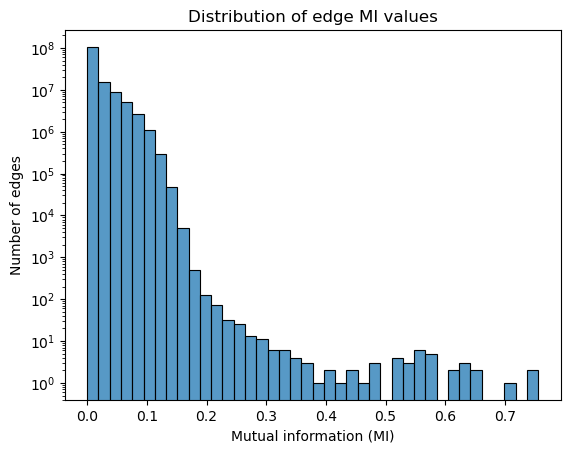

In [9]:
plot_mi_distribution(path_edge)

In [8]:
path_filtered_tsv = "../output/vip_sub_test.tsv"

filtered = pd.read_csv(path_filtered_tsv, sep="\t", index_col="gene")

print(filtered.index[filtered.index.astype(str).str.fullmatch(r"MATR3(\.\d+)?")].tolist())
print(filtered.index.is_unique)

['MATR3']
True
